# Central fotovoltaica · Análisis en Python (corte 3)

Procesa las medidas del ESP32 (sensores INA260) y genera gráficas y tablas.
Ejecutar de arriba abajo: **Kernel → Restart & Run All**. Requiere `pandas`, `numpy`, `matplotlib` y `openpyxl`.

| Nodo | Qué mide |
|---|---|
| entrada (`0x40`) | paneles o batería, según la prueba |
| salida (`0x44`) | salida del elevador MT3608 (5 V) hacia la carga |

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
from fisica import *

SAL = RAIZ / "graficas"; TAB = RAIZ / "tablas"
SAL.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
AZUL, NAR, VERDE, ROJO, GRIS, AMAR = "#004883", "#eb6834", "#1f9d55", "#c0392b", "#5b6672", "#e0a800"
plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.8})
pd.set_option("display.precision", 3)
RES = {}  # números que usa la presentación
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(SAL / nombre, bbox_inches="tight"); plt.show()

## Requerimiento 1 · Procesamiento de datos y modelado físico

### 1.1 Funciones físicas
Definidas en `fisica.py`. Unidades: V, mA, mW, mWh, s, Ω.

| Función | Ecuación |
|---|---|
| `ohm_v`, `ohm_i`, `ohm_r` | V = I · R |
| `potencia` | P = V · I |
| `energia` | E = ∫ P dt (regla del trapecio) |
| `eficiencia` | η = P<sub>sal</sub> / P<sub>ent</sub> · 100 |
| `error_pct` | \|real − teórico\| / \|teórico\| · 100 |

In [2]:
# Prueba rápida de las funciones con valores conocidos.
print("V con 100 mA y 50 Ω   :", ohm_v(100, 50), "V")
print("R con 5 V y 100 mA    :", ohm_r(5.0, 100), "Ω")
print("P con 5 V y 100 mA    :", potencia(5.0, 100), "mW")
print("E de 100 mW por 1 h   :", round(energia(np.arange(0, 3601, 5), np.full(721, 100))[-1], 3), "mWh")
print("η 473 de 547 mW       :", round(eficiencia(473, 547), 1), "%")

V con 100 mA y 50 Ω   : 5.0 V
R con 5 V y 100 mA    : 50.0 Ω
P con 5 V y 100 mA    : 500.0 mW
E de 100 mW por 1 h   : 100.0 mWh
η 473 de 547 mW       : 86.5 %


### 1.2 Importar los datos
Cada Excel que descarga la página del ESP32 trae la hoja `Prueba N`. Se cargan todas en un solo `DataFrame`.
Son 8 pruebas del 19 al 23 de noviembre: 4 de generación con los paneles (de día) y 4 de consumo con la batería (de noche).
P2 y P4 quedaron como "paneles" en la página, pero son de consumo nocturno: el script las toma como batería.

In [3]:
d = cargar()
print(d.shape[0], "filas ·", d.prueba.nunique(), "pruebas")
pruebas = d.groupby("prueba").agg(fuente=("fuente", "first"), nombre=("nombre", "first"), filas=("n", "size"),
                                  inicio=("fecha", "min"), horas=("h", "max"))
display(pruebas)
RES["pruebas"] = {int(p): [r.fuente, int(r.filas), round(r.horas, 2)] for p, r in pruebas.iterrows()}
d.head()

33682 filas · 8 pruebas


,fuente,nombre,filas,inicio,horas
prueba,,,,,
1,paneles,Paneles · Generación energética P01,3649,2026-11-19 12:35:13.114,5.067
2,bateria,Paneles · Consumo energético P11,16,2026-11-19 17:40:01.020,4.612
3,paneles,Paneles · Generación energética P02,1683,2026-11-20 13:49:52.367,2.337
4,bateria,Paneles · Consumo energético P12,4498,2026-11-20 16:10:47.073,14.613
5,paneles,Paneles · Generación energética P03,5611,2026-11-21 06:48:10.389,9.312
6,bateria,Batería · Consumo energético P13,4974,2026-11-21 16:07:28.223,15.769
7,paneles,Paneles · Generación energética P04,5704,2026-11-22 07:54:01.018,7.959
8,bateria,Batería · Consumo energético P14,7547,2026-11-22 16:09:27.367,20.436


,n,fecha,t,V,I,P_esp,E_esp,Vs,Is,Ps_esp,Es_esp,h,nombre,prueba,fuente
0,1,2026-11-19 12:35:13.114,0.114,3.835,141.3,541.885,0.000,4.976,96.3,479.189,0.000,3.167e-05,Paneles · Generación energética P01,1,paneles
1,2,2026-11-19 12:35:18.114,5.114,3.845,138.8,533.686,0.741,4.976,95.0,472.720,0.657,1.421e-03,Paneles · Generación energética P01,1,paneles
2,3,2026-11-19 12:35:23.114,10.114,3.879,122.5,475.178,1.401,4.980,85.0,423.300,1.244,2.809e-03,Paneles · Generación energética P01,1,paneles
3,4,2026-11-19 12:35:28.115,15.115,3.898,111.3,433.847,2.004,4.983,77.5,386.183,1.781,4.199e-03,Paneles · Generación energética P01,1,paneles
4,5,2026-11-19 12:35:33.116,20.116,3.908,103.8,405.650,2.567,4.984,73.8,367.819,2.292,5.588e-03,Paneles · Generación energética P01,1,paneles


### 1.3 Calcular potencia y energía con el script
El ESP32 ya entrega P y E. Aquí se recalculan desde V e I para comprobarlos.
El ESP32 suma la energía por rectángulos; aquí se usa la regla del trapecio.

In [4]:
d["P"] = potencia(d.V, d.I); d["Ps"] = potencia(d.Vs, d.Is)
d["E"] = d.groupby("prueba", group_keys=False).apply(lambda g: pd.Series(energia(g.t, g.P), g.index))
d["Es"] = d.groupby("prueba", group_keys=False).apply(lambda g: pd.Series(energia(g.t, g.Ps), g.index))
d["R_carga"] = ohm_r(d.Vs, d.Is)  # resistencia equivalente de la carga por Ohm
fin = d.groupby("prueba").agg(E_py=("E", "last"), E_esp=("E_esp", "max"), Es_py=("Es", "last"), Es_esp=("Es_esp", "max"))
fin["dif_E_%"] = error_pct(fin.E_esp, fin.E_py)
display(fin.round(2))
print("Diferencia máxima de potencia P = V·I contra el ESP32:", np.nanmax(np.abs(d.P - d.P_esp)).round(3), "mW")
RES["energia"] = {int(p): [round(r.E_py, 1), round(r.E_esp, 1), round(r["dif_E_%"], 2)] for p, r in fin.iterrows()}
RES["dif_P_max"] = round(float(np.nanmax(np.abs(d.P - d.P_esp))), 3)

,E_py,E_esp,Es_py,Es_esp,dif_E_%
prueba,,,,,
1,982.48,982.11,850.77,850.44,0.04
2,5.44,5.19,4.77,4.55,4.94
3,675.86,675.27,570.67,570.18,0.09
4,3332.17,3340.65,2889.98,2896.85,0.25
5,2433.05,2433.06,2142.17,2142.18,0.00
6,3765.48,3765.32,3250.37,3250.19,0.00
7,2546.60,2546.45,2217.29,2217.16,0.01
8,3958.00,3957.91,3413.44,3413.24,0.00


Diferencia máxima de potencia P = V·I contra el ESP32: 0.0 mW


### 1.4 Limpiar los datos
Problemas en las lecturas crudas:
- filas con el sistema apagado al empezar o al terminar cada prueba (0 mA),
- saltos de la tensión de los paneles cuando pasan nubes,
- ruido de ±1 paso del sensor (1.25 mV · 1.25 mA).

Filtro en dos pasos con NumPy: **mediana móvil** de 5 muestras (quita picos) y **media móvil** de 12 muestras = 60 s (suaviza).
El filtro trabaja por tramos: no promedia a través de huecos de más de 60 s.

In [5]:
dl = limpiar(d)
quitadas = (d.groupby("prueba").size() - dl.groupby("prueba").size()).fillna(0).astype(int)
print("Filas quitadas por prueba:"); display(quitadas.to_frame("filas").T)
RES["R_carga"] = {int(p): round(v) for p, v in dl.groupby("prueba").R_carga.median().items()}
# Filtro por prueba para no mezclar el final de una con el inicio de otra.
for c in ["V", "I", "Vs", "Is"]:
    dl[c + "_f"] = dl.groupby("prueba")[c].transform(lambda x: filtrar(x.values, dl.t[x.index].values))

Filas quitadas por prueba:


prueba,1,2,3,4,5,6,7,8
filas,0,3,0,13,64,20,5,13


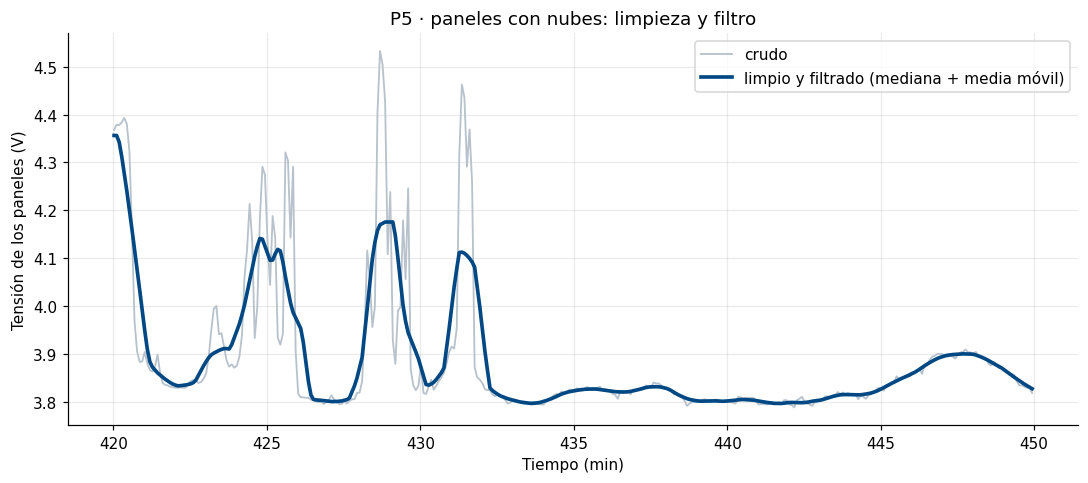

,σ crudo (mV),σ filtrado (mV)
1,19.856,3.314
3,13.495,7.430
4,6.420,0.345
5,29.758,3.687
6,1.054,0.212
7,7.818,4.193
8,2.476,0.344


In [6]:
# P5: media hora con nubes (minutos 420 a 450), cruda frente a la filtrada.
ven = lambda x: x[(x.prueba == 5) & x.t.between(25200, 27000)]
g, gl = ven(d), ven(dl)
fig, ax = plt.subplots()
ax.plot(g.t / 60, g.V, color="#b8c2cc", lw=1.2, label="crudo")
tf, vf = con_huecos(gl.t, gl.V_f)
ax.plot(tf / 60, vf, color=AZUL, lw=2.4, label="limpio y filtrado (mediana + media móvil)")
ax.set(xlabel="Tiempo (min)", ylabel="Tensión de los paneles (V)", title="P5 · paneles con nubes: limpieza y filtro")
ax.legend(); guardar(fig, "r1_limpieza.png")
# Variación entre lecturas seguidas de la salida, antes y después del filtro.
ruido = pd.DataFrame({p: {"σ crudo (mV)": 1000 * np.std(np.diff(g.Vs)), "σ filtrado (mV)": 1000 * np.std(np.diff(g.Vs_f))}
                      for p, g in dl.groupby("prueba") if len(g) > 200}).T
display(ruido.round(3))
RES["limpieza"] = {"filas": int(d.shape[0]), "quitadas": int(quitadas.sum()),
                   "ruido_crudo": round(ruido.iloc[:, 0].median(), 2), "ruido_filtrado": round(ruido.iloc[:, 1].median(), 2)}
RES["serie_crudo"] = g[["t", "V"]].assign(t=g.t / 60).round(3).values.tolist()
RES["serie_filtrado"] = gl[["t", "V_f"]].assign(t=gl.t / 60).round(3).values.tolist()

## Requerimiento 2 · Análisis de datos y eficiencia

### 2.1 Eficiencia del convertidor MT3608
η = P<sub>salida</sub> / P<sub>entrada</sub>. Solo tiene sentido cuando la entrada es la batería.
La descarga de referencia es P8: la más larga, de 3.90 V hasta el corte.

In [7]:
bat = dl[dl.fuente == "bateria"]
ef = bat.groupby("prueba").apply(lambda g: pd.Series({
    "P_ent (mW)": g.P.mean(), "P_sal (mW)": g.Ps.mean(), "pérdida (mW)": (g.P - g.Ps).mean(),
    "E_ent (mWh)": g.E.iloc[-1] - g.E.iloc[0], "E_sal (mWh)": g.Es.iloc[-1] - g.Es.iloc[0],
    "η (%)": eficiencia(g.Es.iloc[-1] - g.Es.iloc[0], g.E.iloc[-1] - g.E.iloc[0]),
    "R carga (Ω)": g.R_carga.median()}), include_groups=False)
ef = ef[bat.groupby("prueba").size() > 100]  # P2 solo tiene 13 filas válidas
display(ef.round(1))
# P8: la eficiencia según la tensión de la batería.
g8 = dl[dl.prueba == 8].copy()
g8["eta"] = eficiencia(g8.Ps, g8.P)
tramos = g8.groupby(pd.cut(g8.V, [2.2, 2.6, 3.0, 3.2, 3.4, 3.5, 3.6, 3.7, 3.9]), observed=True).eta.mean()
display(tramos.round(1).to_frame("η (%)"))
RES["eficiencia"] = {int(k): round(v, 1) for k, v in ef["η (%)"].items()}
RES["perdida"] = {int(k): round(v, 1) for k, v in ef["pérdida (mW)"].items()}
RES["flujo"] = {int(k): [round(r["E_ent (mWh)"]), round(r["E_sal (mWh)"])] for k, r in ef.iterrows()}
RES["eta_vs_v"] = [[round(iv.mid, 2), round(v, 1)] for iv, v in tramos.items()]

,P_ent (mW),P_sal (mW),pérdida (mW),E_ent (mWh),E_sal (mWh),η (%),R carga (Ω)
prueba,,,,,,,
4,544.7,472.0,72.7,3331.9,2889.7,86.7,50.2
6,547.5,472.6,74.9,3765.2,3250.1,86.3,50.9
8,379.6,327.4,52.2,3957.9,3413.3,86.2,74.6


,η (%)
V,
"(2.2, 2.6]",84.6
"(2.6, 3.0]",85.6
"(3.0, 3.2]",86.3
"(3.2, 3.4]",86.7
"(3.4, 3.5]",85.7
"(3.5, 3.6]",86.0
"(3.6, 3.7]",86.5
"(3.7, 3.9]",86.9


### 2.2 Error porcentual: teórico contra real
| Comparación | Teórico | Real |
|---|---|---|
| Potencia | P = V · I (Python) | potencia que guardó el ESP32 |
| Energía | trapecios (Python) | rectángulos del ESP32 |
| Salida del MT3608 | consigna de 5.00 V | tensión medida en `0x44` (solo con batería: con panel se apaga al irse el sol) |
| Corriente de la batería (P8) | potencia constante: I = P<sub>sal</sub> / (η · V) | corriente medida |
| Eficiencia | 97 % (máximo de la hoja de datos) | η medida |
| Autonomía (P4 y P6) | t = E<sub>P8</sub> / P<sub>entrada</sub> | duración medida hasta el corte |

In [8]:
eta0 = g8.eta.median() / 100
g8["I_teo"] = g8.Ps / (eta0 * g8.V)  # el elevador pide más corriente cuando baja la tensión
E_bat = g8.E.iloc[-1] / 1000  # Wh que entregó la batería en P8
auto = ef[["P_ent (mW)"]].set_axis(["P"], axis=1)
auto["t_calc"] = E_bat * 1000 / auto.P
auto["t_med"] = bat.groupby("prueba").h.agg(lambda h: h.max() - h.min())
val = auto.drop(index=8)  # P8 da la energía: se valida con las otras
filas = [
    ["Potencia P = V·I", "todas", np.nanmean(error_pct(dl.P, dl.P_esp))],
    ["Energía (trapecio vs ESP32)", "todas", fin["dif_E_%"].mean()],
    ["Salida 5.00 V", "batería", error_pct(5.0, bat[bat.prueba.isin(ef.index)].Vs).mean()],
    ["Corriente potencia constante", "P8", error_pct(g8.I_teo, g8.I).mean()],
    ["Eficiencia hoja de datos 97 %", "batería", error_pct(97, ef["η (%)"]).mean()],
    ["Autonomía E / P", "P4 y P6", error_pct(val.t_calc, val.t_med).mean()],
]
errores = pd.DataFrame(filas, columns=["Comparación", "Pruebas", "Error medio (%)"])
display(errores.round(3))
RES["errores"] = errores.round(3).values.tolist()
RES["eta0"] = round(eta0 * 100, 1)

,Comparación,Pruebas,Error medio (%)
0,Potencia P = V·I,todas,0.000
1,Energía (trapecio vs ESP32),todas,0.666
2,Salida 5.00 V,batería,0.955
3,Corriente potencia constante,P8,0.692
4,Eficiencia hoja de datos 97 %,batería,10.896
5,Autonomía E / P,P4 y P6,9.998


### 2.3 Modelo de descarga y autonomía
Regresión polinómica de grado 4 de la tensión de la batería contra el tiempo (P8, de 3.90 V hasta el corte).
La autonomía se estima con **t = E<sub>batería</sub> / P<sub>entrada</sub>**, con la energía medida en P8,
y se compara con lo que duraron de verdad P4 y P6.

V(t) = -0.0012·t^4 +0.0212·t^3 -0.1225·t^2 +0.1822·t^1 +3.6629·t^0
R² = 0.9397 · raíz del error cuadrático medio (RMSE) = 57.0 mV


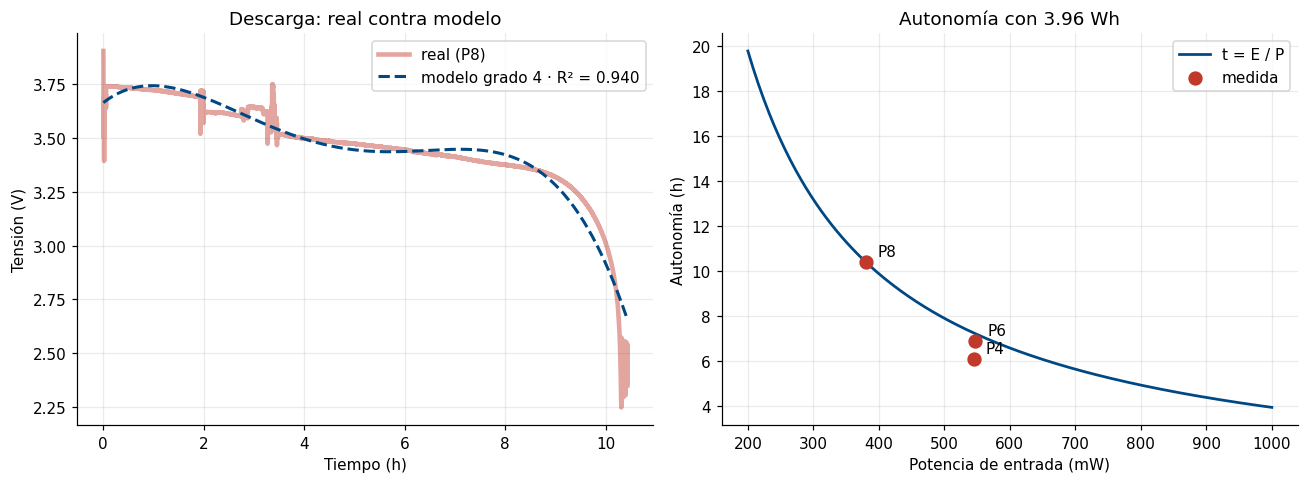

,P,t_calc,t_med
prueba,,,
4,544.73,7.27,6.12
6,547.47,7.23,6.92
8,379.63,10.43,10.42


Pendiente de la meseta (mV/h): {4: -60.7, 6: -34.1, 8: -48.6}


In [9]:
coef = np.polyfit(g8.h, g8.V, 4)
g8["V_mod"] = np.polyval(coef, g8.h)
r2 = 1 - ((g8.V - g8.V_mod) ** 2).sum() / ((g8.V - g8.V.mean()) ** 2).sum()
rmse = np.sqrt(((g8.V - g8.V_mod) ** 2).mean())
print("V(t) =", " ".join(f"{c:+.4f}·t^{4 - k}" for k, c in enumerate(coef)))
print(f"R² = {r2:.4f} · raíz del error cuadrático medio (RMSE) = {1000 * rmse:.1f} mV")
P = np.linspace(200, 1000, 200)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(g8.h, g8.V, color=ROJO, lw=3, alpha=.45, label="real (P8)")
ax[0].plot(g8.h, g8.V_mod, "--", color=AZUL, lw=2, label=f"modelo grado 4 · R² = {r2:.3f}")
ax[0].set(xlabel="Tiempo (h)", ylabel="Tensión (V)", title="Descarga: real contra modelo"); ax[0].legend()
ax[1].plot(P, E_bat * 1000 / P, color=AZUL, label="t = E / P")
ax[1].scatter(auto.P, auto.t_med, color=ROJO, s=70, zorder=4, label="medida")
for p, r in auto.iterrows():
    ax[1].annotate(f"P{p}", (r.P, r.t_med), xytext=(8, 4), textcoords="offset points")
ax[1].set(xlabel="Potencia de entrada (mW)", ylabel="Autonomía (h)", title=f"Autonomía con {E_bat:.2f} Wh"); ax[1].legend()
guardar(fig, "r2_descarga_autonomia.png")
display(auto.round(2))
pend = bat[bat.prueba.isin(ef.index) & (bat.V > 3.3)].groupby("prueba").apply(lambda g: 1000 * np.polyfit(g.h, g.V, 1)[0], include_groups=False)
print("Pendiente de la meseta (mV/h):", pend.round(1).to_dict())
RES["modelo"] = {"coef": coef.round(5).tolist(), "r2": round(r2, 4), "rmse_mV": round(1000 * rmse, 1), "E_Wh": round(E_bat, 3),
                 "t_corte": round(g8.h.max(), 2), "P8_mW": round(g8.P.mean(), 1), "n": int(len(g8))}
RES["autonomia"] = {int(p): [round(r.P, 1), round(r.t_calc, 2), round(r.t_med, 2)] for p, r in auto.iterrows()}
RES["pendiente"] = {int(k): round(v, 1) for k, v in pend.items()}
paso = max(1, len(g8) // 140)
cols = ["h", "V", "V_mod", "I", "I_teo"]
RES["serie_descarga"] = pd.concat([g8[cols].iloc[::paso], g8[cols].iloc[[-1]]]).drop_duplicates().round(3).values.tolist()  # incluye el corte final
RES["V_corte"] = round(g8.V.iloc[-1], 2)

### 2.4 Detectar pérdidas y caídas de tensión
- **Pérdida en el elevador**: E<sub>entrada</sub> − E<sub>salida</sub> en cada descarga.
- **Saltos bruscos**: `np.diff` sobre la tensión; se marca todo salto mayor que 8 veces la variación típica, con un mínimo de 50 mV.

prueba,1,2,3,4,5,6,7,8
saltos,52.0,1.0,16.0,115.0,233.0,4.0,126.0,124.0
mayor_mV,625.0,1036.0,147.0,412.0,906.0,192.0,1165.0,326.0


,E_ent (mWh),E_sal (mWh),perdida,perdida_%
prueba,,,,
4,3331.9,2889.7,442.2,13.3
6,3765.2,3250.1,515.1,13.7
8,3957.9,3413.3,544.5,13.8


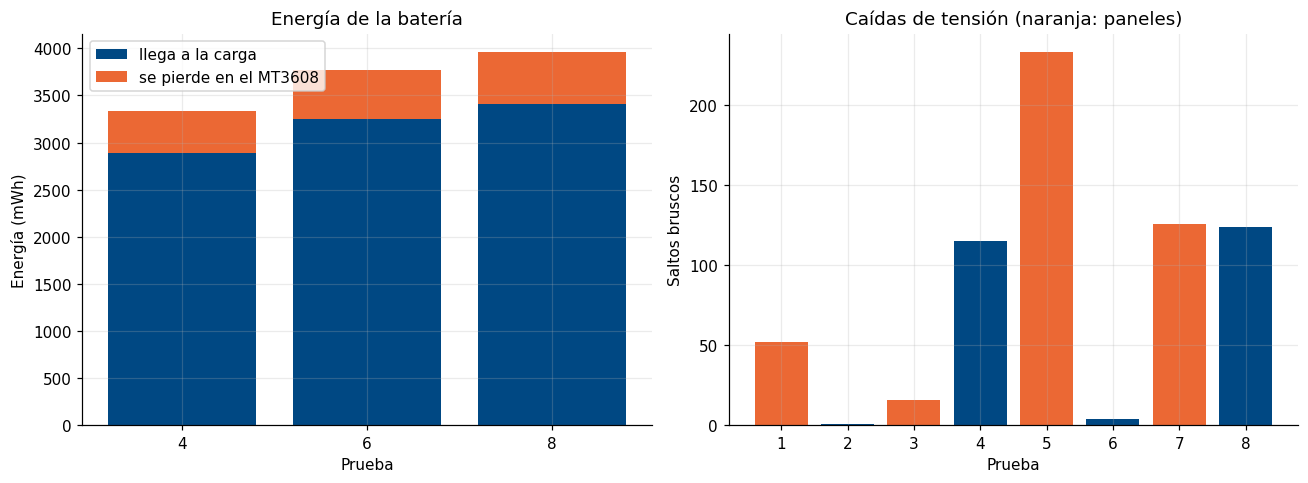

In [10]:
eventos = []
for p, g in dl.groupby("prueba"):
    c = caidas(g.t.values, g.V.values, g.I.values)
    eventos.append(c.assign(prueba=p))
ev = pd.concat(eventos)
resumen_ev = ev.groupby("prueba").agg(saltos=("dV", "size"), mayor_mV=("dV", lambda x: 1000 * x.abs().max()))
resumen_ev = resumen_ev.reindex(dl.prueba.unique(), fill_value=0)
display(resumen_ev.T.round(0))
perd = ef[["E_ent (mWh)", "E_sal (mWh)"]].assign(perdida=lambda x: x.iloc[:, 0] - x.iloc[:, 1])
perd["perdida_%"] = 100 * perd.perdida / perd["E_ent (mWh)"]
display(perd.round(1))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
x = perd.index.astype(str)
ax[0].bar(x, perd["E_sal (mWh)"], color=AZUL, label="llega a la carga")
ax[0].bar(x, perd.perdida, bottom=perd["E_sal (mWh)"], color=NAR, label="se pierde en el MT3608")
ax[0].set(xlabel="Prueba", ylabel="Energía (mWh)", title="Energía de la batería"); ax[0].legend()
ax[1].bar(resumen_ev.index.astype(str), resumen_ev.saltos, color=[NAR if f == "paneles" else AZUL for f in pruebas.fuente[resumen_ev.index]])
ax[1].set(xlabel="Prueba", ylabel="Saltos bruscos", title="Caídas de tensión (naranja: paneles)")
guardar(fig, "r2_perdidas.png")
RES["perdidas"] = {"saltos": int(len(ev)), "por_prueba": {int(p): int(v) for p, v in resumen_ev.saltos.items()},
                   "mayor_mV": round(float(resumen_ev.mayor_mV.max())), "pct": {int(p): round(v, 1) for p, v in perd["perdida_%"].items()}}

## Requerimiento 3 · Visualización y validación de resultados

### 3.1 Curvas superpuestas: teórico contra real

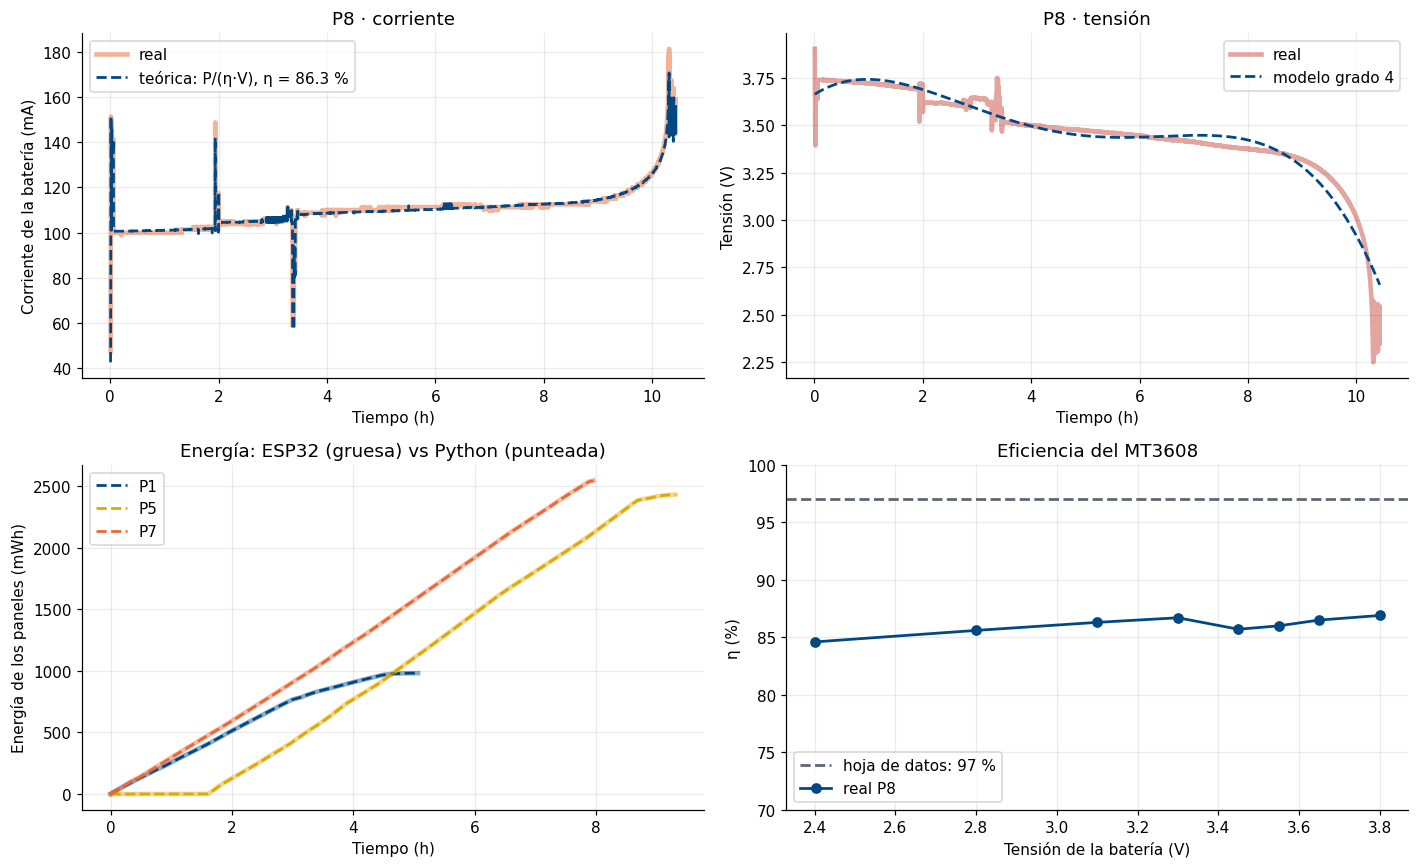

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
ax[0, 0].plot(g8.h, g8.I, color=NAR, lw=3, alpha=.5, label="real")
ax[0, 0].plot(g8.h, g8.I_teo, "--", color=AZUL, label=f"teórica: P/(η·V), η = {eta0 * 100:.1f} %")
ax[0, 0].set(xlabel="Tiempo (h)", ylabel="Corriente de la batería (mA)", title="P8 · corriente"); ax[0, 0].legend()
ax[0, 1].plot(g8.h, g8.V, color=ROJO, lw=3, alpha=.45, label="real")
ax[0, 1].plot(g8.h, g8.V_mod, "--", color=AZUL, label="modelo grado 4")
ax[0, 1].set(xlabel="Tiempo (h)", ylabel="Tensión (V)", title="P8 · tensión"); ax[0, 1].legend()
for p, c in [(1, AZUL), (5, AMAR), (7, NAR)]:
    g = d[d.prueba == p]
    ax[1, 0].plot(g.h - g.h.iloc[0], g.E_esp, color=c, lw=3, alpha=.45)
    ax[1, 0].plot(g.h - g.h.iloc[0], g.E, "--", color=c, label=f"P{p}")
ax[1, 0].set(xlabel="Tiempo (h)", ylabel="Energía de los paneles (mWh)", title="Energía: ESP32 (gruesa) vs Python (punteada)"); ax[1, 0].legend()
v, e = zip(*RES["eta_vs_v"])
ax[1, 1].axhline(97, color=GRIS, ls="--", label="hoja de datos: 97 %")
ax[1, 1].plot(v, e, "o-", color=AZUL, label="real P8")
ax[1, 1].set(xlabel="Tensión de la batería (V)", ylabel="η (%)", ylim=(70, 100), title="Eficiencia del MT3608"); ax[1, 1].legend()
guardar(fig, "r3_teorico_vs_real.png")

### 3.2 Tablas resumen para el informe

In [12]:
resumen = dl.groupby("prueba").agg(fuente=("fuente", "first"), horas=("h", "max"), muestras=("n", "size"),
    V_media=("V", "mean"), V_min=("V", "min"), V_max=("V", "max"), I_media=("I", "mean"),
    P_media=("P", "mean"), E_mWh=("E", "last"), Vs_media=("Vs", "mean"), Is_media=("Is", "mean"), Ps_media=("Ps", "mean"))
por_fuente = dl.groupby("fuente")[["V", "I", "P", "Vs", "Is", "Ps"]].describe().T
display(resumen.round(3)); display(por_fuente.round(3))
resumen.round(4).to_csv(TAB / "resumen_pruebas.csv", encoding="utf-8-sig")
with pd.ExcelWriter(TAB / "tablas_corte3.xlsx") as x:
    for nombre, t in {"Resumen": resumen, "Por fuente": por_fuente, "Eficiencia": ef, "Errores": errores.set_index("Comparación"),
                      "Autonomía": auto, "Eventos": resumen_ev}.items():
        t.round(4).to_excel(x, sheet_name=nombre)
print("Tablas guardadas en tablas/")
RES["resumen"] = resumen.reset_index()[["prueba", "fuente", "horas", "V_media", "P_media", "E_mWh"]].round(3).values.tolist()

,fuente,horas,muestras,V_media,V_min,V_max,I_media,P_media,E_mWh,Vs_media,Is_media,Ps_media
prueba,,,,,,,,,,,,
1,paneles,5.067,3649,3.895,2.027,5.330,47.025,193.915,982.480,4.327,36.297,167.920
2,bateria,4.607,13,2.913,2.039,3.075,101.923,312.738,5.188,4.518,55.385,274.051
3,paneles,2.337,1683,3.564,3.276,3.761,80.229,289.199,675.857,4.492,52.832,244.189
4,bateria,6.124,4485,3.493,2.220,3.874,157.563,544.726,3332.170,4.966,95.072,472.033
5,paneles,9.312,5547,3.893,2.299,5.195,80.356,315.804,2433.049,4.830,56.401,278.049
6,bateria,6.984,4954,3.444,2.175,3.790,159.423,547.466,3765.480,4.962,95.231,472.569
7,paneles,7.959,5699,3.870,3.060,5.114,83.630,321.817,2546.600,4.981,56.215,280.202
8,bateria,10.432,7534,3.458,2.248,3.904,110.398,379.630,3957.997,4.938,66.303,327.381


fuente      bateria    paneles
V  count  16986.000  16578.000
   mean       3.463      3.852
   std        0.221      0.519
   min        2.039      2.027
   25%        3.404      3.626
   50%        3.490      3.808
   75%        3.595      4.166
   max        3.904      5.330
I  count  16986.000  16578.000
   mean     137.143     74.132
   std       29.405     21.674
   min        2.500      2.500
   25%      111.300     60.000
   50%      131.300     80.000
   75%      162.500     88.800
   max      292.500    161.300
P  count  16986.000  16578.000
   mean     472.120    288.341
   std       90.922     85.179
   min        5.098      5.068
   25%      380.365    259.548
   50%      478.589    311.781
   75%      570.251    346.849
   max      967.150    541.886
Vs count  16986.000  16578.000
   mean       4.952      4.737
   std        0.037      0.591
   min        2.041      2.050
   25%        4.948      4.971
   50%        4.960      4.983
   75%        4.963      4.989
   max        5.020      5.006
Is count  16986.000  16578.000
   mean      82.328     51.550
   std       15.627     13.582
   min        2.500      2.500
   25%       66.300     46.300
   50%       85.000     55.000
   75%       98.800     60.000
   max      163.800    117.500
Ps count  16986.000  16578.000
   mean     407.879    251.111
   std       78.247     77.196
   min        5.102      5.125
   25%      328.052    225.045
   50%      421.940    274.065
   75%      490.147    299.700
   max      805.077    479.189

Tablas guardadas en tablas/


### 3.3 Estabilidad de la tensión
Desviación estándar (σ) con `np.std` y coeficiente de variación CV = σ / media.
La salida del MT3608 debe ser estable; la batería baja poco a poco y el panel cambia con el sol.

,fuente,Vs media (V),σ Vs (mV),CV Vs (%),σ V entrada (mV)
prueba,,,,,
1,paneles,4.327,886.179,20.480,806.233
2,bateria,4.518,1055.688,23.365,372.808
3,paneles,4.492,476.711,10.613,152.196
4,bateria,4.966,8.169,0.165,253.706
5,paneles,4.830,501.054,10.374,444.970
6,bateria,4.962,2.719,0.055,158.466
7,paneles,4.981,86.101,1.729,372.943
8,bateria,4.938,21.508,0.436,232.145


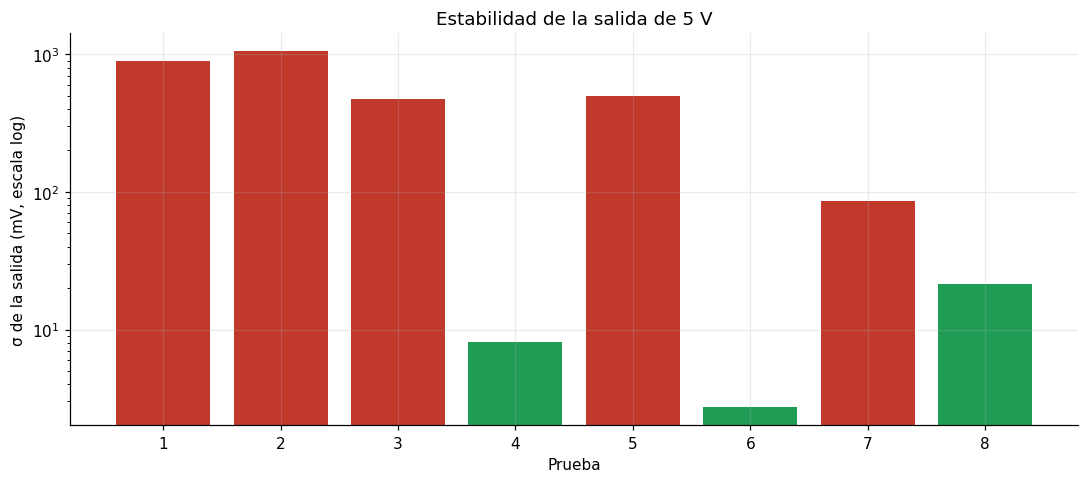

In [13]:
est = dl.groupby("prueba").apply(lambda g: pd.Series({
    "fuente": g.fuente.iat[0], "Vs media (V)": np.mean(g.Vs), "σ Vs (mV)": 1000 * np.std(g.Vs),
    "CV Vs (%)": 100 * np.std(g.Vs) / np.mean(g.Vs), "σ V entrada (mV)": 1000 * np.std(g.V)}), include_groups=False)
display(est.round(3))
fig, ax = plt.subplots()
col = [VERDE if s < 25 else ROJO for s in est["σ Vs (mV)"]]
ax.bar(est.index.astype(str), est["σ Vs (mV)"], color=col)
ax.set(yscale="log", xlabel="Prueba", ylabel="σ de la salida (mV, escala log)", title="Estabilidad de la salida de 5 V")
guardar(fig, "r3_estabilidad.png")
RES["estabilidad"] = {int(p): [r.fuente, round(r["Vs media (V)"], 3), round(r["σ Vs (mV)"], 2)] for p, r in est.iterrows()}

### 3.4 Datos para la presentación
Se guardan los números que usan las diapositivas, para que salgan del mismo cálculo.

In [14]:
(RAIZ / "resultados.json").write_text(json.dumps(RES, ensure_ascii=False, default=float), encoding="utf-8")
print("resultados.json listo ·", len(RES), "bloques")

resultados.json listo · 21 bloques
